In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import scipy.stats as stats

# Set seed for reproducibility
np.random.seed(42)

# Generate synthetic data
n_samples = 200
X1 = np.random.normal(loc=10, scale=2, size=n_samples)  # Feature 1
X2 = np.random.normal(loc=5, scale=1, size=n_samples)   # Feature 2
# True relationship: y = 3.5 * X1 + 2.0 * X2 + Noise
noise = np.random.normal(loc=0, scale=1.5, size=n_samples)
y = 3.5 * X1 + 2.0 * X2 + noise

# Create DataFrame
df = pd.DataFrame({'Feature1': X1, 'Feature2': X2, 'Target': y})
display(df.head())

,Feature1,Feature2,Target
0,10.993428,5.357787,46.800932
1,9.723471,5.560785,44.254656
2,11.295377,6.083051,51.707788
3,13.046060,6.053802,57.839284
4,9.531693,3.622331,39.930489


In [2]:
# Train-test split
X_simple = df[['Feature1']]
y_target = df['Target']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_target, test_size=0.2, random_state=42)

# Initialize and fit model
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

# Predictions
y_pred_s = simple_model.predict(X_test_s)

# Evaluation
rmse_s = np.sqrt(mean_squared_error(y_test_s, y_pred_s))
r2_s = r2_score(y_test_s, y_pred_s)

print(f"Simple Regression Coefficients: {simple_model.coef_[0]:.4f}")
print(f"Simple Regression Intercept: {simple_model.intercept_:.4f}")
print(f"Simple Regression RMSE: {rmse_s:.4f}")
print(f"Simple Regression R²: {r2_s:.4f}")

Simple Regression Coefficients: 3.5329
Simple Regression Intercept: 9.6113
Simple Regression RMSE: 2.6485
Simple Regression R²: 0.8233


## 2. Multiple Linear Regression
Now we will fit a multiple linear regression model using both `Feature1` and `Feature2`.

In [3]:
# Train-test split using both features
X_multi = df[['Feature1', 'Feature2']]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_target, test_size=0.2, random_state=42)

# Initialize and fit model
multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)

# Predictions
y_pred_m = multi_model.predict(X_test_m)

# Evaluation
rmse_m = np.sqrt(mean_squared_error(y_test_m, y_pred_m))
r2_m = r2_score(y_test_m, y_pred_m)

print(f"Multiple Regression Coefficients: {multi_model.coef_}")
print(f"Multiple Regression Intercept: {multi_model.intercept_:.4f}")
print(f"Multiple Regression RMSE: {rmse_m:.4f}")
print(f"Multiple Regression R²: {r2_m:.4f}")

Multiple Regression Coefficients: [3.4109055 1.9628879]
Multiple Regression Intercept: 0.8530
Multiple Regression RMSE: 1.4635
Multiple Regression R²: 0.9460


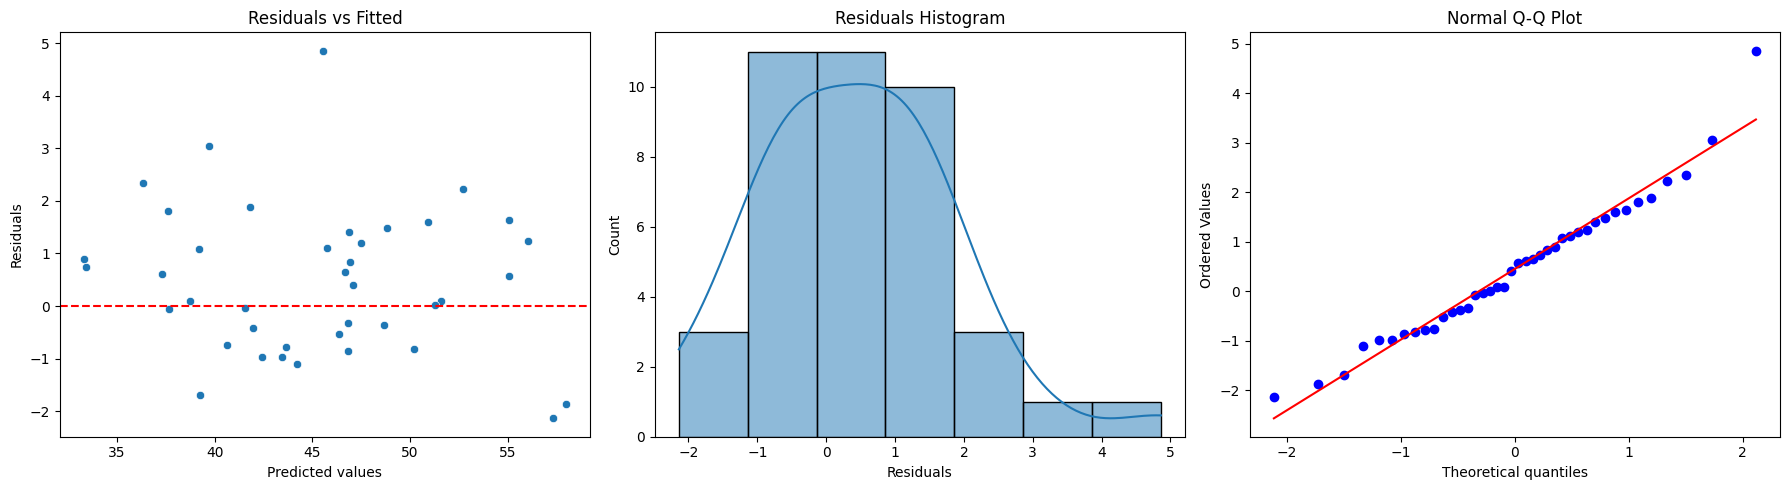

In [4]:
# Calculate residuals
residuals = y_test_m - y_pred_m

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Residuals vs Predicted (Checking Homoscedasticity and Linearity)
sns.scatterplot(x=y_pred_m, y=residuals, ax=axes[0])
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_title('Residuals vs Fitted')
axes[0].set_xlabel('Predicted values')
axes[0].set_ylabel('Residuals')

# 2. Distribution of Residuals (Checking Normality)
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title('Residuals Histogram')
axes[1].set_xlabel('Residuals')

# 3. Q-Q Plot (Checking Normality)
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title('Normal Q-Q Plot')

plt.tight_layout()
plt.show()